In [26]:
from astroquery.sdss import SDSS
from astropy import coordinates as coords
import astropy.units as u
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [23]:
query = """
SELECT TOP 1000
    specObjID,
    ra,
    dec,
    z,
    class,
    subclass,
    sciencePrimary
FROM SpecObj
WHERE class = 'STAR'
  AND zWarning = 0
  AND sciencePrimary = 1
"""

query2 = """
SELECT TOP 20 *
FROM PhotoProfile
"""

query3 = """
SELECT TOP 50000
p.objid,p.ra,p.dec,p.u,p.g,p.r,p.i,p.z,
p.run, p.rerun, p.camcol,
s.specobjid, s.class, s.z as redshift,
s.plate, s.mjd, s.fiberid
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestobjid = p.objid
WHERE 
  p.u BETWEEN 0 AND 19.6
  AND g BETWEEN 0 AND 20
  AND class = 'STAR'
"""

results_stars = SDSS.query_sql(query3)
df_stars = results_stars.to_pandas()

print(df_stars.shape)
df_stars.head()

(50000, 17)


,objid,ra,dec,u,g,r,i,z,run,rerun,camcol,specobjid,class,redshift,plate,mjd,fiberid
0,1237657189814894804,322.179348,-0.887370,19.12087,18.14939,17.85088,17.74750,17.69529,2728,301,1,4936150902698694656,STAR,-0.000719,4384,56105,748
1,1237657189814894794,322.169915,-0.978392,18.36163,17.43443,17.15849,17.02772,16.98199,2728,301,1,10385420995456686080,STAR,-0.000787,9224,57933,437
2,1237657189814894786,322.161288,-0.949588,18.81571,17.29359,16.74793,16.55831,16.44329,2728,301,1,1112455120936790016,STAR,-0.000203,988,52520,240
3,1237657189814894716,322.136165,-0.987971,17.03644,15.93133,15.74105,15.68707,15.69192,2728,301,1,2207967288236284928,STAR,0.000030,1961,53299,282
4,1237657189814894697,322.127552,-1.026576,19.06291,18.06267,17.73943,17.58143,17.51347,2728,301,1,10335892665523263488,STAR,-0.000434,9180,57693,478


In [24]:
query4 = """
SELECT TOP 50000
p.objid,p.ra,p.dec,p.u,p.g,p.r,p.i,p.z,
p.run, p.rerun, p.camcol,
s.specobjid, s.class, s.z as redshift,
s.plate, s.mjd, s.fiberid
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestobjid = p.objid
WHERE class = 'GALAXY'
"""

results_galaxy = SDSS.query_sql(query4)
df_galaxy = results_galaxy.to_pandas()

print(df_galaxy.shape)
df_galaxy.head(90)

(50000, 17)


,objid,ra,dec,u,g,r,i,z,run,rerun,camcol,specobjid,class,redshift,plate,mjd,fiberid
0,1237646382079542274,94.636981,0.974963,17.14729,15.61818,15.41421,15.62225,15.27046,211,301,6,1417598466720294912,GALAXY,0.000000,1259,52931,329
1,1237646549575401765,49.397831,1.273562,20.94433,20.27348,19.87477,19.66730,19.82965,250,301,6,800638565766686720,GALAXY,0.169056,711,52202,450
2,1237646549576712337,52.384716,1.273285,19.84410,18.61294,17.88917,17.43708,17.17084,250,301,6,466289168801097728,GALAXY,0.109002,414,51869,606
3,1237646585544901720,40.378762,-0.833787,23.51124,22.25629,21.93526,20.70458,20.02142,259,301,1,10550924710698571776,GALAXY,0.856035,9371,58073,424
4,1237646585564037815,84.093255,-0.833462,25.64150,21.68955,20.86932,20.55171,20.14648,259,301,1,2332870162081933312,GALAXY,0.243797,2072,53430,20
5,1237646585565086037,86.504306,-0.986007,23.14278,21.18512,19.10863,17.96941,17.14363,259,301,1,8170734625620252672,GALAXY,0.988841,7257,56658,287
6,1237646585565151273,86.541249,-0.934797,21.52511,18.68376,16.84261,15.82592,15.11223,259,301,1,1402910941472909312,GALAXY,0.539331,1246,54478,144
7,1237646585565216992,86.799395,-0.851498,23.82355,21.33790,19.35242,18.19046,17.36950,259,301,1,8170725554649323520,GALAXY,0.969372,7257,56658,254
8,1237646585565282459,86.953904,-0.876872,24.59196,20.58630,18.61079,17.48596,16.67815,259,301,1,1404079692117469184,GALAXY,0.757408,1247,52677,300
9,1237646585565282508,86.895230,-0.840155,24.50640,21.93433,19.79359,18.43270,17.44713,259,301,1,8170710986120255488,GALAXY,0.975606,7257,56658,201


<Figure size 640x480 with 0 Axes>

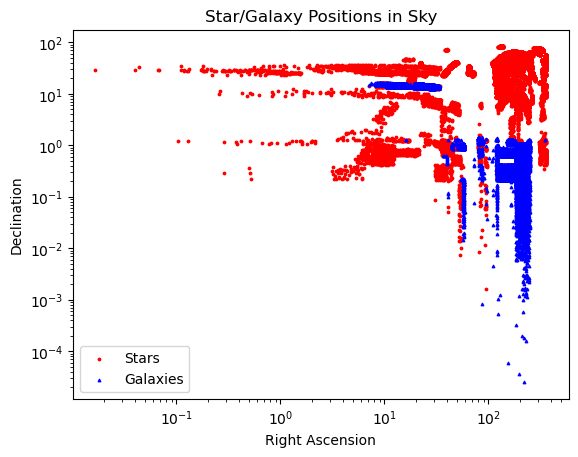

<Figure size 640x480 with 0 Axes>

In [27]:
plt.scatter(df_stars["ra"], df_stars["dec"], color='red', label= "Stars", s= 3, marker='o')
plt.scatter(df_galaxy["ra"], df_galaxy["dec"], color='blue', label="Galaxies",s=3, marker='^')
plt.legend()
#plt.plot(df["ra"], df["dec"])
plt.title("Star/Galaxy Positions in Sky")
plt.xlabel("Right Ascension")
plt.ylabel("Declination")
plt.xscale("log")
plt.yscale("log")
plt.figure()

<SkyCoord (ICRS): (ra, dec) in deg
    (180., 0.5)>


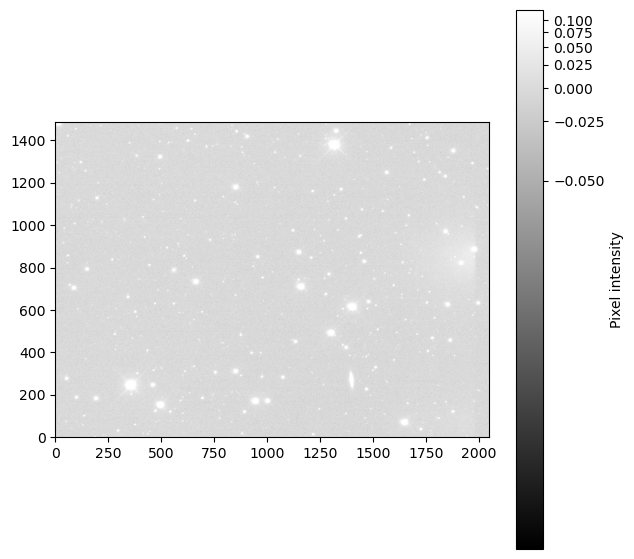

In [33]:
#Producing a picture from stellar information
from astroquery.sdss import SDSS
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, LogStretch, ZScaleInterval


# Example RA and Dec (degrees)
coord = SkyCoord(ra=180.0*u.degree, dec=0.5*u.degree)

print(coord)

# Retrieve SDSS image
#images = SDSS.get_images(coordinates=coord, band='g', data_release=17)

row = df_galaxy.iloc[5]

images = SDSS.get_images(
    run=int(row["run"]),
    rerun=int(row["rerun"]),
    camcol=int(row["camcol"]),
    band="g")

# Display image
image_data = images[0][0].data
norm = ImageNormalize(image_data, interval=ZScaleInterval(), stretch=LogStretch())

plt.figure(figsize=(7,7))
plt.imshow(image_data, cmap='gray', origin='lower', norm=norm)
plt.colorbar(label='Pixel intensity')
plt.show()

In [35]:
from astroquery.sdss import SDSS
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt


query4 = """
SELECT TOP 50000
p.objid,p.ra,p.dec,p.u,p.g,p.r,p.i,p.z,
p.run, p.rerun, p.camcol,
s.specobjid, s.class, s.z as redshift,
s.plate, s.mjd, s.fiberid
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestobjid = p.objid
WHERE class = 'GALAXY'
"""

results_galaxy = SDSS.query_sql(query4)
df_galaxy = results_galaxy.to_pandas()

#print(df_galaxy.shape)
df_galaxy.head(90)



for index, row in df_galaxy.head(5).iterrows():
    coord = SkyCoord(ra=row["ra"] * u.degree, dec=row["dec"] * u.degree)
    images = SDSS.get_images(coordinates=coord,band="z")
    #image_data = images[0][0].data
    norm = ImageNormalize(image_data, interval=ZScaleInterval(), stretch=LogStretch())
    plt.figure(figsize=(5,5))
    plt.imshow(images[0][0].data, cmap="gray", origin="lower", norm = norm)
    plt.title(f"Galaxy {row['objid']}")
    plt.show()

KeyError: 'run'

In [29]:
#Test Query Station 

'''
test_query = """
SELECT
    TABLE_NAME,
    COLUMN_NAME,
    DATA_TYPE,
    ORDINAL_POSITION
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_NAME IN (
    'SpecObj',
    'SpecObjAll',
    'galSpecLine',
    'galSpecIndx',
    'galSpecExtra',
    'galSpecInfo'
)
"""
'''
test_query = """
SELECT
    TABLE_NAME,
    COLUMN_NAME,
    DATA_TYPE,
    ORDINAL_POSITION
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_NAME IN (
    'SpecObj',
    'SpecObjAll',
    'galSpecLine',
    'galSpecIndx',
    'galSpecExtra',
    'galSpecInfo'
)
"""

query = SDSS.query_sql(test_query)
results = query.to_pandas()

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
#print(results.shape)
#print(results.head(90))

InconsistentTableError: Number of header columns (1) inconsistent with data columns in data line 9

In [ ]:
'''
Project Information:

Question 1: In pictures of stars/galaxies in the SDSS dataset, when we reduce the information what is considered important features?
Procedure 1: Use CCA to find maximally correlated features in the dataset, and through pixel analysis/image plots/scatterplots confirm 
or deny this

Question 2: Can we find a way to approximately "weigh" galaxies utilizing PCA like we do with stars?
Procedure 2: Perform PCA on large dataset of galaxy spectrum data to compress information into small # of principal components, then 
project on galactic population synthesis codes to estimate galactic mass/mass-to-light ratio. These principal components should capture
the major variations in the galactic spectrum data. ISOLATE INDIVIDUAL GALAXY SPECTRA

Methods: PCA, CCA, SVD
Diagnostic Plots: ScatterPlots, Mass-to-Light Ratio (pictures), Image Plots, Sky Distribution Plot, Redshift Distribution, 
Redshift Versus Brightness

In [31]:
#Exploratory Data Analysis (EDA)

test_query = """
SELECT TOP 50000
s.FIBERID, s.MJD, s.WAVEMIN, p.objid,p.ra,p.dec,p.u,p.g,p.r,p.i,p.z,
p.run, p.rerun, p.camcol,
s.specobjid, s.class, s.z as redshift,
s.plate, s.mjd, s.fiberid
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestobjid = p.objid
WHERE class = 'GALAXY'
"""

query = SDSS.query_sql(test_query)
results = query.to_pandas()

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
#print(nrow(results))
results.head(90)

,FIBERID,MJD,WAVEMIN,objid,ra,dec,u,g,r,i,z,run,rerun,camcol,specobjid,class,redshift,plate,mjd1,fiberid1
0,85,55503,3601.637,1237645879573873373,41.019613,1.271279,22.64928,22.00960,20.40414,19.57801,19.20975,94,301,6,4797482960004864000,GALAXY,0.504868,4261,55503,85
1,156,58932,3601.637,1237648720135390235,130.731015,-0.918340,22.75761,22.08015,21.75870,21.60107,21.33163,756,301,1,14101939364012775424,GALAXY,0.591841,12525,58932,156
2,147,58932,3601.637,1237648720135390487,130.715643,-1.034325,23.88660,23.03087,21.56724,20.25216,19.66039,756,301,1,14101936890111612928,GALAXY,0.717501,12525,58932,147
3,146,58932,3601.637,1237648720135455441,130.762872,-1.013727,21.24462,19.79819,18.80876,18.41234,18.04467,756,301,1,14101936615233705984,GALAXY,0.152093,12525,58932,146
4,143,58932,3601.637,1237648720135455545,130.749441,-0.954400,22.08829,20.70564,20.23840,19.99213,19.82723,756,301,1,14101935790599985152,GALAXY,0.180546,12525,58932,143
5,247,51883,3808.904,1237648720145481973,153.762442,-0.997308,20.57385,18.64201,17.66163,17.22909,16.88417,756,301,1,305186801188890624,GALAXY,0.098219,271,51883,247
6,248,51883,3808.904,1237648720145482111,153.668460,-0.993711,19.33273,17.78174,17.27654,16.98632,16.76277,756,301,1,305187076066797568,GALAXY,0.059772,271,51883,248
7,244,51883,3808.904,1237648720145547522,153.898219,-1.001506,19.16637,17.45534,16.65019,16.24938,15.93866,756,301,1,305185976555169792,GALAXY,0.083658,271,51883,244
8,245,51883,3808.904,1237648720145547565,153.831485,-1.009414,19.67307,18.35104,17.54550,17.06732,16.75602,756,301,1,305186251433076736,GALAXY,0.164296,271,51883,245
9,246,51883,3808.904,1237648720145547571,153.850133,-0.989025,20.63587,18.50025,17.35936,16.76465,16.31428,756,301,1,305186526310983680,GALAXY,0.201606,271,51883,246


In [32]:
#Plotting one galactic Spectrum 

spectrum = SDSS.get_spectra(plate = 416, fiberID = 417, mjd = 51811)

spec = spectrum[0]
spec.info()

data = spec[1].data
print(data.columns.names)

#Converting Wavelength from Log10()
wavelength = 10**data['loglam']
flux = data['flux']

#Ploting
plt.figure(figsize=(5,5))
plt.plot(wavelength, flux)
plt.title(f"Galaxy Spectra")
plt.ylabel("Flux")
plt.xlabel(r'$X_{i} = Y^2$')
plt.show()

InconsistentTableError: Number of header columns (1) inconsistent with data columns in data line 9

In [151]:
#Main Project Dataset SQL Query

project_query = """
SELECT TOP 50000
p.objid,p.ra,p.dec,p.u,p.g,p.r,p.i,p.z,
p.run, p.rerun, p.camcol, p.field,
s.specobjid, s.class, s.z as redshift,
s.plate, s.mjd, s.fiberid
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestobjid = p.objid
WHERE class = 'GALAXY'
"""

projected_query = SDSS.query_sql(project_query)
project_dataset = projected_query.to_pandas()

#galaxy = project_dataset[project_dataset["class"] == "GALAXY"]
#stars = project_dataset[project_dataset["class"] == "STAR"]

project_dataset.head(100)

,objid,ra,dec,u,g,r,i,z,run,rerun,camcol,field,specobjid,class,redshift,plate,mjd,fiberid
0,1237648703509102769,196.554898,-0.664147,19.00659,17.46996,16.69207,16.29661,16.01036,752,301,2,354,331066557855721472,GALAXY,0.083987,294,51986,189
1,1237648703509102812,196.612641,-0.806041,18.73435,16.83528,15.89845,15.49562,15.14348,752,301,2,354,331052539082467328,GALAXY,0.084177,294,51986,138
2,1237648703509102821,196.623459,-0.797385,19.27567,17.23888,16.27929,15.86932,15.52172,752,301,2,354,4561040403370104832,GALAXY,0.084211,4051,55337,72
3,1237648703509103348,196.615205,-0.636579,25.68008,22.66198,20.91925,19.99116,19.48007,752,301,2,354,4561053322631731200,GALAXY,0.496519,4051,55337,119
4,1237648703509364815,197.208802,-0.817319,15.93799,13.99257,13.07748,12.59386,12.25992,752,301,2,358,331029724216190976,GALAXY,0.017943,294,51986,55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1237648703511265559,201.539544,-0.698491,20.06272,18.85290,17.87767,17.40519,17.06526,752,301,2,387,334428863960475648,GALAXY,0.236622,297,51959,133
96,1237648703511265898,201.475489,-0.790065,24.57052,21.35569,19.70087,18.80297,18.24421,752,301,2,387,4559969758318188544,GALAXY,0.489517,4050,55599,273
97,1237648703511266033,201.536352,-0.727392,24.13095,22.28228,20.66024,19.56784,18.90986,752,301,2,387,4559957663690283008,GALAXY,0.568011,4050,55599,229
98,1237648704046759994,198.356363,-0.328044,25.28078,21.70171,20.15480,19.37002,18.84982,752,301,3,366,4508209144264939520,GALAXY,0.411272,4004,55321,385
